# Many channels: where the $\Omega d$ problem is real

Notebook 01 found that with one channel the transfer matrix can be used safely: reflection and transmission never need the part of the matrix that rounding destroys. That argument rests on a single direction being carried through the stack. With $n$ channels, a birefringent layer ($n=2$) or the $n$ Fourier orders of a grating, $n$ independent solutions have to be carried at once, and the argument fails. This notebook shows the failure on two structures whose exact response is of order one and well conditioned, gives its law, and compares the three kinds of cure.

## What this notebook shows

- A uniaxial slab between two prisms, at an angle where one of its waves propagates and the other is evanescent. For s incidence the transmitted power is of order one at every thickness. Both transfer-matrix conventions return it with a relative error $\epsilon\,e^{\kappa d}$, which reaches one at $\kappa d=\ln(1/\epsilon)\approx36$, a slab of some fifteen wavelengths here.
- The mechanism is the collapse of a frame. The $n$ outgoing solutions, carried back through the slab as $n$ vectors, all turn toward the fastest-growing wave. They still span the right plane in exact arithmetic, but the stored vectors determine it with an error $\epsilon$ times the condition number of the frame, which grows as $e^{(\kappa_{\max}-\kappa_{\min})d}$.
- The plane itself is well behaved, and every stable method is a way of carrying the plane without the frame: in a chart (the reflection matrix; this is the scattering-matrix and enhanced-transmittance recursions), as an orthonormal frame (re-orthogonalization), or in Plücker coordinates (the compound or "delta" matrix of the elastic-wave literature). All of them, and a global linear system, stay at rounding level past the thickness at which the transfer matrix overflows.
- A lamellar grating in the Fourier modal method: the number of channels is the truncation order, the fastest decay grows with it, and the transfer matrix turns a convergence study into noise at an order that the depth of the grating fixes.

## Conventions

As in notebook 01: $e^{-i\omega t}$, lengths in free-space wavelengths, $\beta=k_x/k_0$. A region that is uniform along $z$ is described by its modes, $\Psi(z)=F^+e^{iq^+z}a^++F^-e^{iq^-z}a^-$, where $\Psi$ holds the $2n$ field components that are continuous at interfaces and "forward" modes $q^+$ decay or carry power toward $+z$. For anisotropic layers $\Psi=(E_x,E_y,H_x,H_y)$ with $H$ in units that make the vacuum impedance one; the amplitude of an s wave is its $E_y$ and that of a p wave its $H_y$, as in notebook 01.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/omega_d (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, warnings, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # multilayer.py sits next to this notebook
import multilayer as ml
import mpmath as mp

warnings.filterwarnings("ignore", category=RuntimeWarning)   # overflow is part of the subject here
EPS = np.finfo(float).eps
LN_INV_EPS = np.log(1 / EPS)
K0 = ml.K0
print(f"ln(1/eps) = {LN_INV_EPS:.2f}")

ln(1/eps) = 36.04


## 1. The transfer matrix with $n$ channels

The fields at the entrance are $F_a\,(a_{\rm in},\,r)$ and at the exit $F_b\,(t,\,0)$, where $F=(F^+\;F^-)$ and $a_{\rm in}$, $r$, $t$ are now vectors of $n$ amplitudes. With $N=\prod_jT_j^{-1}$ carrying the exit fields to the entrance,

$$\begin{pmatrix}a_{\rm in}\\r\end{pmatrix}=K\begin{pmatrix}t\\0\end{pmatrix},\qquad K=F_a^{-1}NF_b,\qquad T=K_{11}^{-1},\quad R=K_{21}K_{11}^{-1}.$$

For $n=1$ the block $K_{11}$ is a number and its inverse costs nothing. For $n\ge2$ it is a matrix whose columns are the $n$ outgoing waves of medium $b$ after their passage through the stack, and each column is dominated by whichever wave of the stack grows fastest in that direction. The other convention, entrance to exit, needs $K_{22}^{-1}$ and the Schur complement $K_{11}-K_{12}K_{22}^{-1}K_{21}$ and is no better.

### The structure

A slab of a positive uniaxial material, $n_o=1.5$ and $n_e=1.7$ (the size of the birefringence of a nematic liquid crystal), with its axis in the plane of the layers at $45^\circ$ to the plane of incidence, between two prisms of index 1.8. At $\beta=1.55$ the ordinary wave is evanescent in the slab and the extraordinary wave propagates. Because the axis is neither in the plane of incidence nor normal to it, s and p are both coupled to both waves at the faces.

The first checks are of the solver: the wavenumbers of the slab against the closed forms for a uniaxial medium, the isotropic limit of the 4-vector code against the one-channel code of notebook 01, and the multiprecision reference against flux conservation and reciprocity. For this slab, which is its own mirror image in its mid-plane and is unchanged by a half turn about $z$, reciprocity relates the two cross-polarized transmissions at the same $\beta$: $t_{sp}\,w_s=t_{ps}\,w_p$, with $w$ the power carried per unit squared amplitude. The relation follows from the conserved bilinear form of two solutions, one incident from each side.

In [3]:
n_o, n_e, n_pr, beta, phi_c = 1.5, 1.7, 1.8, 1.55, np.radians(45)
eps_u = ml.uniaxial(n_o ** 2, n_e ** 2, np.pi / 2, phi_c)
M_slab = ml.modes_aniso(eps_u, beta)
G_slab = ml.berreman_G(eps_u, beta)
M_pr = ml.modes_iso4(n_pr ** 2, beta)

nz_o = np.sqrt(complex(n_o ** 2 - beta ** 2))
nz_e = np.sqrt(complex(n_e ** 2 - beta ** 2 * (np.sin(phi_c) ** 2 + n_e ** 2 / n_o ** 2 * np.cos(phi_c) ** 2)))
print("forward modes of the slab, q/k0:", np.round(M_slab.qp / K0, 6), "  closed forms: e", np.round(nz_e, 6), " o", np.round(nz_o, 6))
check("extraordinary wavenumber against the closed form", abs(M_slab.qp[0] / K0 - nz_e), 1e-12)
check("ordinary wavenumber against the closed form", abs(M_slab.qp[1] / K0 - nz_o), 1e-12)
check("backward modes are minus the forward ones", np.abs(np.sort_complex(M_slab.qm) - np.sort_complex(-M_slab.qp)).max() / K0, 1e-12)
kap = M_slab.qp.imag.max()
print(f"decay rate of the ordinary wave: kappa = {kap:.4f} per wavelength; kappa d = {LN_INV_EPS:.2f} at d = {LN_INV_EPS / kap:.2f} wavelengths")

# isotropic limit: three isotropic layers through the 4x4 code against the one-channel code, both polarizations
st_iso = ml.Stack(n_pr ** 2, [(2.0, 0.31), (6.0 + 0.2j, 0.17), (1.3, 0.42)], 1.0)
b_iso = 0.7
Ma_i, Mb_i = ml.modes_iso4(st_iso.eps_a, b_iso), ml.modes_iso4(st_iso.eps_b, b_iso)
L_i = [(ml.modes_aniso(e * np.eye(3), b_iso), d) for e, d in st_iso.layers]
S_i = ml.block_S(Ma_i, L_i, Mb_i)
worst = 0.0
for j, pol in enumerate("sp"):
    ea, ls, eb = st_iso.params(b_iso, pol)
    r1, t1 = ml.rt_from_backward(ml.T_backward(ls), ea, eb)
    worst = max(worst, abs(S_i[0][j, j] - r1), abs(S_i[2][j, j] - t1), abs(S_i[0][1 - j, j]), abs(S_i[2][1 - j, j]))
check("isotropic layers through the 4x4 code: r, t of s and p against notebook 01, and no cross-polarization", worst, 1e-12)


def reference(d):
    """(R, T) of the slab of thickness d, multiprecision."""
    return ml.ref_block_rt(M_pr, [(G_slab, d)], M_pr, int(60 + 2 * kap * d / np.log(10)))


g_pr = np.sqrt(n_pr ** 2 - beta ** 2)
W_FLUX = np.array([g_pr, g_pr / n_pr ** 2])           # power per unit |amplitude|^2 for s (E_y) and p (H_y) in the prism


def powers(R, T, inc):
    """Reflected and transmitted power for unit incident power in polarization inc (0 = s, 1 = p)."""
    R, T = np.asarray(R), np.asarray(T)
    return (abs(R[:, inc]) ** 2 * W_FLUX).sum() / W_FLUX[inc], (abs(T[:, inc]) ** 2 * W_FLUX).sum() / W_FLUX[inc]


to_np = lambda X: np.array([[complex(X[i, j]) for j in range(X.cols)] for i in range(X.rows)])
worst = 0.0
for d in (0.3, 3.0, 30.0):
    Rr, Tr = (to_np(X) for X in reference(d))
    for inc in (0, 1):
        worst = max(worst, abs(sum(powers(Rr, Tr, inc)) - 1))
    worst = max(worst, abs(Tr[0, 1] * W_FLUX[0] - Tr[1, 0] * W_FLUX[1]) / abs(Tr).max())      # reciprocity: t_sp w_s = t_ps w_p
check("reference: R + T = 1 for s and p incidence, and t_sp w_s = t_ps w_p, three thicknesses", worst, 1e-13)

forward modes of the slab, q/k0: [0.381852+0.j       0.      +0.390512j]   closed forms: e (0.381852+0j)  o 0.390512j
PASS  extraordinary wavenumber against the closed form: got 4.50954e-16, target 0, |diff| 4.51e-16 <= 1e-12
PASS  ordinary wavenumber against the closed form: got 2.5513e-16, target 0, |diff| 2.55e-16 <= 1e-12
PASS  backward modes are minus the forward ones: got 4.08153e-16, target 0, |diff| 4.08e-16 <= 1e-12
decay rate of the ordinary wave: kappa = 2.4537 per wavelength; kappa d = 36.04 at d = 14.69 wavelengths
PASS  isotropic layers through the 4x4 code: r, t of s and p against notebook 01, and no cross-polarization: got 7.4476e-16, target 0, |diff| 7.45e-16 <= 1e-12
PASS  reference: R + T = 1 for s and p incidence, and t_sp w_s = t_ps w_p, three thicknesses: got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-13


### What the transfer matrix returns

The slab is made thicker and everything else is kept. The transmitted power for s incidence (left) oscillates because the extraordinary wave makes round trips in the slab; nothing about it becomes small or sensitive. The right panel is the error of the transmission matrix, the largest entry error over the largest entry.

200 thicknesses, 1.8 s


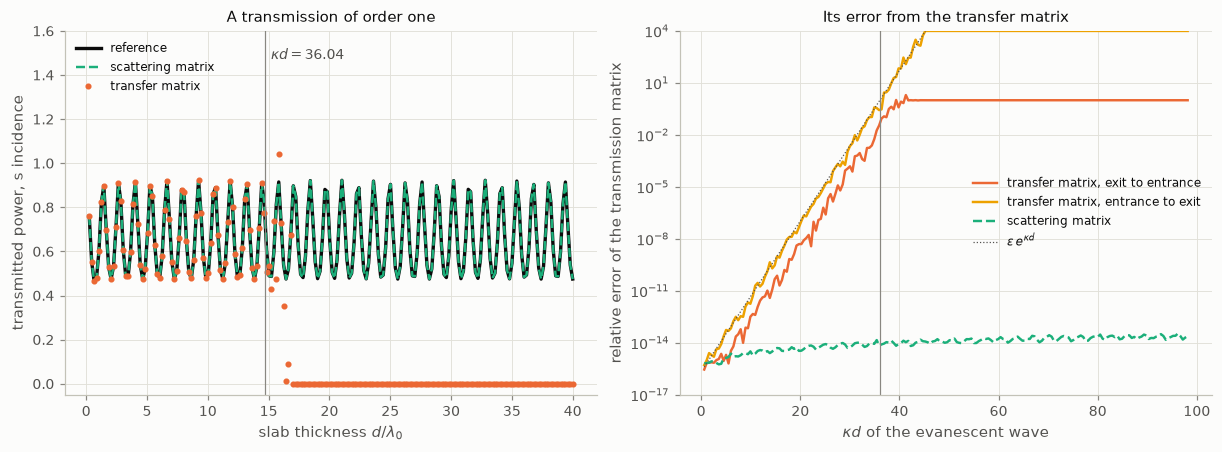

PASS  exponent of the transfer-matrix error, d ln(error) / d(kappa d): got 0.971991, target 1, |diff| 2.80e-02 <= 1e-01
PASS  kappa d at which the error of the transmission first exceeds 0.1: got 36.882, target 36.0437, |diff| 8.38e-01 <= 4e+00
exact transmitted power over the scan: 0.467 to 0.923
PASS  largest error of the scattering matrix over the scan (transmission and reflection): got 3.51324e-14, target 0, |diff| 3.51e-14 <= 1e-12


In [4]:
ds = np.linspace(0.25, 40.0, 200)
names = ["transfer matrix, exit to entrance", "transfer matrix, entrance to exit", "scattering matrix", "enhanced transmittance",
         "orthonormal frame", "global matrix", "Plücker coordinates"]
err_T = {k: [] for k in names[:6]}
err_R = {k: [] for k in names}
P_ref, P_T, P_S = [], [], []
t0 = time.time()
for d in ds:
    Rr, Tr = reference(d)
    L = [(M_slab, d)]
    out = {names[0]: ml.block_T(M_pr, L, M_pr), names[1]: ml.block_T(M_pr, L, M_pr, "forward"),
           names[2]: (lambda S: (S[0], S[2]))(ml.block_S(M_pr, L, M_pr)), names[3]: ml.block_ETM(M_pr, L, M_pr),
           names[4]: ml.block_QR(M_pr, L, M_pr), names[5]: ml.block_global(M_pr, L, M_pr)[:2]}
    for k, (R, T) in out.items():
        err_T[k].append(ml.mp_err(T, Tr)); err_R[k].append(ml.mp_err(R, Rr))
    err_R[names[6]].append(ml.mp_err(ml.compound_R(M_pr, L, M_pr)[0], Rr))
    P_ref.append(powers(to_np(Rr), to_np(Tr), 0)[1])
    P_T.append(powers(*out[names[0]], 0)[1]); P_S.append(powers(*out[names[2]], 0)[1])
err_T = {k: np.array(v) for k, v in err_T.items()}
err_R = {k: np.array(v) for k, v in err_R.items()}
P_ref, P_T, P_S = np.array(P_ref), np.array(P_T), np.array(P_S)
print(f"{len(ds)} thicknesses, {time.time() - t0:.1f} s")

FLOOR = 1e-17
clip = lambda e: np.clip(np.where(np.isfinite(e), e, 1e30), FLOOR, 1e4)
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax = axes[0]
ax.plot(ds, P_ref, color=INK, lw=2.2, label="reference")
ax.plot(ds, P_S, color=CAT[2], ls="--", label="scattering matrix")
ax.plot(ds, np.clip(np.where(np.isfinite(P_T), P_T, 9.0), -0.2, 1.6), "o", ms=3, color=CAT[1], label="transfer matrix")
ax.axvline(LN_INV_EPS / kap, color=MUTED, lw=0.8)
ax.text(LN_INV_EPS / kap + 0.5, 1.52, r"$\kappa d=36.04$", color=INK2, fontsize=9, va="top")
ax.set(xlabel=r"slab thickness $d/\lambda_0$", ylabel="transmitted power, s incidence", ylim=(-0.05, 1.6),
       title="A transmission of order one")
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
ax.semilogy(kap * ds, clip(err_T[names[0]]), color=CAT[1], label=names[0])
ax.semilogy(kap * ds, clip(err_T[names[1]]), color=CAT[3], label=names[1])
ax.semilogy(kap * ds, clip(err_T[names[2]]), color=CAT[2], ls="--", label=names[2])
ax.semilogy(kap * ds, EPS * np.exp(kap * ds), color=INK2, lw=0.8, ls=":", label=r"$\epsilon\,e^{\kappa d}$")
ax.axvline(LN_INV_EPS, color=MUTED, lw=0.8)
ax.set(xlabel=r"$\kappa d$ of the evanescent wave", ylabel="relative error of the transmission matrix", ylim=(1e-17, 1e4),
       title="Its error from the transfer matrix")
ax.legend(loc="center right", fontsize=8)
plt.show()

sel = (err_T[names[0]] > 1e-12) & (err_T[names[0]] < 1e-2)
slope = np.polyfit(kap * ds[sel], np.log(err_T[names[0]][sel]), 1)[0]
check("exponent of the transfer-matrix error, d ln(error) / d(kappa d)", slope, 0.15, 1.0)
first = kap * ds[np.argmax(err_T[names[0]] > 0.1)]
check("kappa d at which the error of the transmission first exceeds 0.1", first, 4.0, LN_INV_EPS)
print(f"exact transmitted power over the scan: {P_ref.min():.3f} to {P_ref.max():.3f}")
assert P_ref.min() > 0.3
check("largest error of the scattering matrix over the scan (transmission and reflection)", max(err_T[names[2]].max(), err_R[names[2]].max()), 1e-12)

The exponent is one, not the two of notebook 01, and the threshold is at $\ln(1/\epsilon)$ and not at half of it. There the competition was between $e^{+\kappa d}$ and $e^{-\kappa d}$ in the same channel. Here it is between $e^{\kappa d}$ in the evanescent channel and the order-one amplitude of the propagating channel, which is the one that carries the answer.

## 2. The mechanism: a frame collapses, the plane does not

The object that the stack hands from its exit to its entrance is the set of fields at the entrance face that become purely outgoing at the exit. It is an $n$-dimensional subspace of $\mathbb C^{2n}$, a point of the Grassmannian $\mathrm{Gr}(n,2n)$, and $R$ is one way of writing down which point: in the mode basis of medium $a$ the plane is the column space of $\binom{Y_1}{Y_2}$ and $R=Y_2Y_1^{-1}$.

The transfer matrix represents this plane by a frame, the $n$ columns of $NF_b^+$. A frame is a redundant description: any invertible $n\times n$ matrix applied to its columns gives another frame of the same plane. In the course of the product the columns align with the fastest-growing wave, the frame becomes nearly singular, and extracting the plane from it costs a factor equal to its condition number. The cell below measures both for the slab: the condition number of the frame, and the distance (sine of the largest principal angle) between the plane it spans in double precision and the exact plane.

In [5]:
print("   d    kappa d   condition number of the frame   exp(kappa d)   distance of its plane from the exact one   eps x condition")
rows = []
for d in (1.0, 4.0, 8.0, 12.0, 14.0, 16.0, 20.0):
    Q = ml.ref_plane([(G_slab, d)], M_pr.Fp, int(80 + 2 * kap * d / np.log(10)))
    Phi = M_slab.T(-d) @ M_pr.Fp
    sv = np.linalg.svd(Phi, compute_uv=False)
    dist = ml.plane_distance(Q, Phi)
    # the same plane from a frame that is re-orthonormalized on the way
    Phi_q, _ = np.linalg.qr(M_pr.Fp)
    steps = int(np.ceil(kap * d / 5))
    for _ in range(steps):
        Phi_q, _ = np.linalg.qr(M_slab.T(-d / steps) @ Phi_q)
    rows.append([kap * d, sv[0] / sv[-1], dist, ml.plane_distance(Q, Phi_q)])
    print(f"{d:5.1f} {kap * d:9.1f} {sv[0] / sv[-1]:25.3e} {np.exp(kap * d):18.3e} {dist:28.3e} {EPS * sv[0] / sv[-1]:25.1e}")
rows = np.array(rows)
ok = rows[:, 1] < 1e13
check("ln(condition number) - kappa d, spread over the rows below 1e13 (a constant prefactor)", np.ptp(np.log(rows[ok, 1]) - rows[ok, 0]), 1.0)
check("largest distance of the re-orthonormalized frame's plane from the exact one", rows[:, 3].max(), 1e-12)
mid = (rows[:, 2] > 1e-12) & (rows[:, 2] < 1e-1)
print(f"distance / (eps x condition number) where the distance is between 1e-12 and 0.1: {(rows[mid, 2] / (EPS * rows[mid, 1])).min():.2f} to {(rows[mid, 2] / (EPS * rows[mid, 1])).max():.2f}")
assert np.all(rows[mid, 2] < 10 * EPS * rows[mid, 1])

   d    kappa d   condition number of the frame   exp(kappa d)   distance of its plane from the exact one   eps x condition
  1.0       2.5                 7.259e+00          1.163e+01                    1.011e-15                   1.6e-15
  4.0       9.8                 1.737e+04          1.830e+04                    2.707e-12                   3.9e-12
  8.0      19.6                 3.083e+08          3.349e+08                    5.228e-08                   6.8e-08
 12.0      29.4                 5.196e+12          6.128e+12                    3.723e-04                   1.2e-03
 14.0      34.4                 4.566e+14          8.290e+14                    4.320e-02                   1.0e-01
 16.0      39.3                 8.543e+16          1.121e+17                    3.393e-01                   1.9e+01
 20.0      49.1                 2.721e+16          2.052e+21                    8.951e-01                   6.0e+00
PASS  ln(condition number) - kappa d, spread over the rows below

Under the flow from exit to entrance the plane converges to something simple. One of its directions becomes the fastest-growing wave, and the other is fixed by the remaining waves; nothing in it is large or small. This is the many-channel form of the contraction of notebook 01, where the plane was a line. What breaks is only the description by $n$ separately stored vectors, and there are three standard ways to describe a point of a Grassmannian without them.

**A chart.** Fix a splitting of $\mathbb C^{2n}$ into two halves and write the plane as the graph of a matrix from one half to the other. With the forward and backward waves of the current layer as the two halves this matrix is the reflection matrix seen from inside the layer, and its propagation is a matrix Riccati recursion containing only $e^{iq^+d}$ and $e^{-iq^-d}$, both decaying. The scattering-matrix algorithm with the Redheffer star product is this recursion carried for both ends of the stack at once, and the enhanced transmittance matrix method of Moharam and coworkers is the same recursion in homogeneous form, with the troublesome factor moved into the transmitted amplitudes.

**An orthonormal frame.** Keep a frame but remove the redundancy at every step by a QR factorization, as in the computation of Lyapunov exponents. The triangular factors hold the growth and go into the transmission. A thick layer has to be cut into steps over which the growth is moderate.

**Plücker coordinates.** Describe the plane by the $n\times n$ minors of its frame, a single vector in $\Lambda^n\mathbb C^{2n}$, which changes only by a common factor when the frame is changed. For $n=2$ these are six numbers obeying one quadratic relation. A layer acts on them by its second compound matrix, whose entries are the $2\times2$ minors of the transfer matrix. In the mode basis that matrix is diagonal with exponents $q_a+q_b$, one for each pair of modes, and the largest belongs to the pair of growing waves, which is the plane being looked for. Carrying one vector, the dominant behavior is the wanted one, as it was for $n=1$. This is the delta-matrix method that Dunkin and Thrower introduced for elastic waves in 1965; here it is used for the reflection matrix, whose entries are ratios of Plücker coordinates.

A fourth method does not propagate anything: the global matrix writes all interface conditions as one banded linear system for the amplitudes in every layer, with forward amplitudes referred to entrance faces and backward ones to exit faces, and leaves the rest to Gaussian elimination with pivoting.

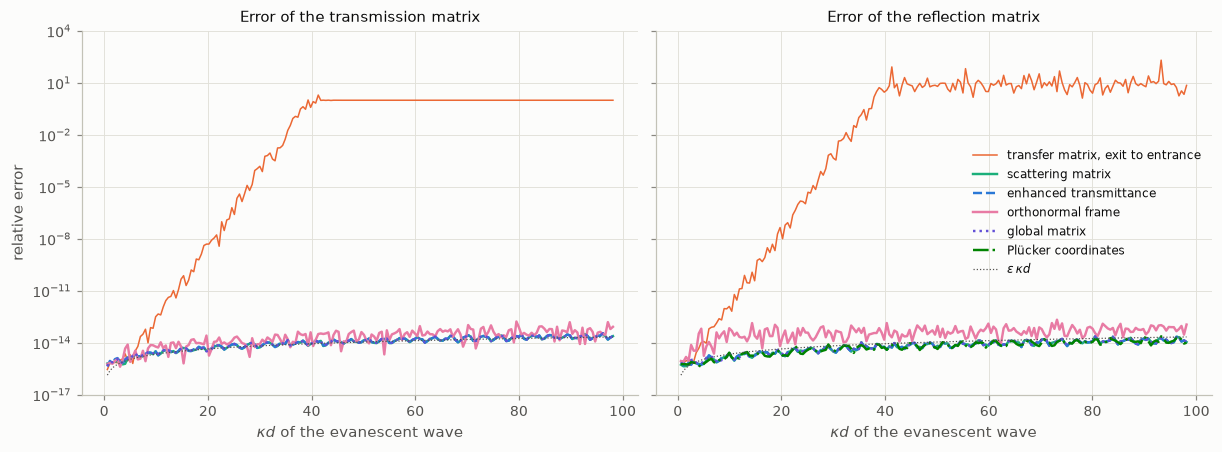

PASS  scattering matrix: largest error of R and T over the scan: got 3.51324e-14, target 0, |diff| 3.51e-14 <= 2e-12
PASS  enhanced transmittance: largest error of R and T over the scan: got 3.56335e-14, target 0, |diff| 3.56e-14 <= 2e-12
PASS  orthonormal frame: largest error of R and T over the scan: got 2.1482e-13, target 0, |diff| 2.15e-13 <= 2e-12
PASS  global matrix: largest error of R and T over the scan: got 3.55208e-14, target 0, |diff| 3.55e-14 <= 2e-12
PASS  Plücker coordinates: largest error of R over the scan: got 2.36552e-14, target 0, |diff| 2.37e-14 <= 2e-12


d = 290 wavelengths, kappa d = 712; transfer matrix finite: False
PASS    scattering matrix: error of R and T: got 1.60772e-13, target 0, |diff| 1.61e-13 <= 1e-11
PASS    enhanced transmittance: error of R and T: got 1.60905e-13, target 0, |diff| 1.61e-13 <= 1e-11
PASS    orthonormal frame: error of R and T: got 1.9655e-13, target 0, |diff| 1.97e-13 <= 1e-11
PASS    global matrix: error of R and T: got 1.60751e-13, target 0, |diff| 1.61e-13 <= 1e-11
PASS    Plücker coordinates: error of R: got 5.71009e-14, target 0, |diff| 5.71e-14 <= 1e-11


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0), sharey=True)
styles = {names[2]: (CAT[2], "-"), names[3]: (CAT[0], "--"), names[4]: (CAT[4], "-"), names[5]: (CAT[6], ":"), names[6]: (CAT[5], "-.")}
for ax, err, what in ((axes[0], err_T, "transmission matrix"), (axes[1], err_R, "reflection matrix")):
    ax.semilogy(kap * ds, clip(err[names[0]]), color=CAT[1], lw=1.0, label=names[0])
    for k, (c, ls) in styles.items():
        if k in err:
            ax.semilogy(kap * ds, clip(err[k]), color=c, ls=ls, label=k)
    ax.semilogy(kap * ds, EPS * kap * ds, color=INK2, lw=0.8, ls=":", label=r"$\epsilon\,\kappa d$")
    ax.set(xlabel=r"$\kappa d$ of the evanescent wave", ylim=(1e-17, 1e4), title=f"Error of the {what}")
axes[0].set_ylabel("relative error")
axes[1].legend(loc="center right", fontsize=8)
plt.show()

for k in names[2:6]:
    check(f"{k}: largest error of R and T over the scan", max(err_T[k].max(), err_R[k].max()), 2e-12)
check(f"{names[6]}: largest error of R over the scan", err_R[names[6]].max(), 2e-12)

# thicker still, where the transfer matrix overflows
d_big = 290.0
Rr, Tr = reference(d_big)
L = [(M_slab, d_big)]
big = {names[2]: (lambda S: (S[0], S[2]))(ml.block_S(M_pr, L, M_pr)), names[3]: ml.block_ETM(M_pr, L, M_pr),
       names[4]: ml.block_QR(M_pr, L, M_pr), names[5]: ml.block_global(M_pr, L, M_pr)[:2]}
print(f"d = {d_big:.0f} wavelengths, kappa d = {kap * d_big:.0f}; transfer matrix finite: {np.all(np.isfinite(ml.block_T(M_pr, L, M_pr)[1]))}")
for k, (R, T) in big.items():
    check(f"  {k}: error of R and T", max(ml.mp_err(R, Rr), ml.mp_err(T, Tr)), 1e-11)
check(f"  {names[6]}: error of R", ml.mp_err(ml.compound_R(M_pr, L, M_pr)[0], Rr), 1e-11)

### The compound matrix in numbers

The six exponents of the second compound matrix of the slab, and the Plücker relation $p_{01}p_{23}-p_{02}p_{13}+p_{03}p_{12}=0$ evaluated on the propagated coordinates. The relation is not imposed by the algorithm, so its residual measures how far rounding has moved the six numbers off the Grassmannian.

In [7]:
qq = np.concatenate([M_slab.qp, M_slab.qm])
labels = ["e+", "o+", "e-", "o-"]
print("pair of modes   (q_a + q_b)/k0             growth of |exp(-i (q_a + q_b) d)| per wavelength, exit to entrance")
for i, j in ml.PAIRS:
    s = (qq[i] + qq[j]) / K0
    print(f"   {labels[i]} {labels[j]}       {s.real:+.4f} {s.imag:+.4f}i        {(qq[i] + qq[j]).imag:+8.3f}")
check("largest growth exponent of the compound matrix is that of the two forward modes", max((qq[i] + qq[j]).imag for i, j in ml.PAIRS), 1e-9, (qq[0] + qq[1]).imag)
worst = 0.0
for d in (1.0, 10.0, 40.0, 290.0):
    _, p, _ = ml.compound_R(M_pr, [(M_slab, d)], M_pr)
    worst = max(worst, abs(p[0] * p[5] - p[1] * p[4] + p[2] * p[3]) / np.abs(p).max() ** 2)
check("residual of the Plucker relation after propagation, four thicknesses", worst, 1e-12)

pair of modes   (q_a + q_b)/k0             growth of |exp(-i (q_a + q_b) d)| per wavelength, exit to entrance
   e+ o+       +0.3819 +0.3905i          +2.454
   e+ e-       +0.0000 +0.0000i          +0.000
   e+ o-       +0.3819 -0.3905i          -2.454
   o+ e-       -0.3819 +0.3905i          +2.454
   o+ o-       +0.0000 -0.0000i          -0.000
   e- o-       -0.3819 -0.3905i          -2.454
PASS  largest growth exponent of the compound matrix is that of the two forward modes: got 2.45366, target 2.45366, |diff| 4.44e-16 <= 1e-09
PASS  residual of the Plucker relation after propagation, four thicknesses: got 4.44385e-16, target 0, |diff| 4.44e-16 <= 1e-12


## 3. A grating: the number of channels is a numerical parameter

The setting in which optics met this problem is the Fourier modal method for gratings (rigorous coupled-wave analysis). The field in a lamellar grating layer is expanded in $2M+1$ Fourier orders along $x$; for $\mathbf E$ along the grooves the amplitudes obey $u''+Au=0$ with $A=k_0^2[\![\varepsilon]\!]-K_x^2$, where $[\![\varepsilon]\!]$ is the Toeplitz matrix of Fourier coefficients of the permittivity and $K_x$ the diagonal matrix of $k_{x,m}=k_0\beta_0+2\pi m/\Lambda$. The layer is an $n$-channel layer with $n=2M+1$, and its fastest decay is about $2\pi M/\Lambda$: it grows with the truncation. Convergence with $M$ is what a user of the method has to check, and with the transfer matrix the check itself destroys the result.

The structure: a glass grating ($\varepsilon=2.25$) on a glass substrate, period $\Lambda=1.5\lambda_0$, half filled, illuminated from air at $10^\circ$. The quantity is the efficiency of the transmitted zeroth order.

In [8]:
period, fill, eps_g, beta0 = 1.5, 0.5, 2.25, np.sin(np.radians(10))


def grating(M, depth):
    A, kx = ml.grating_A(eps_g, 1.0, fill, period, beta0, M)
    Ma, Mb, Mg = ml.modes_sl(ml.uniform_A(1.0, kx)), ml.modes_sl(ml.uniform_A(eps_g, kx)), ml.modes_sl(A)
    n = 2 * M + 1
    G = np.block([[np.zeros((n, n)), np.eye(n)], [-A, np.zeros((n, n))]])
    return Ma, [(Mg, depth)], Mb, G


def efficiencies(R, T, Ma, Mb, M):
    """Diffraction efficiencies of the propagating reflected and transmitted orders for incidence in order 0."""
    qa, qb = Ma.qp, Mb.qp
    with np.errstate(invalid="ignore", over="ignore"):
        Rm = np.where(abs(qa.imag) < 1e-9, abs(R[:, M]) ** 2 * qa.real / qa[M].real, 0.0)
        Tm = np.where(abs(qb.imag) < 1e-9, abs(T[:, M]) ** 2 * qb.real / qa[M].real, 0.0)
    return Rm, Tm


# checks of the grating solver: against the reference at small truncation, energy balance, the methods against each other
worst_ref, worst_bal, worst_agree = 0.0, 0.0, 0.0
for M, depth in ((3, 0.5), (5, 1.0), (5, 2.0)):
    Ma, L, Mb, G = grating(M, depth)
    kd = L[0][0].qp.imag.max() * depth
    Rr, Tr = ml.ref_block_rt(Ma, [(G, depth)], Mb, int(60 + 2 * kd / np.log(10)))
    S = ml.block_S(Ma, L, Mb)
    worst_ref = max(worst_ref, ml.mp_err(S[0], Rr), ml.mp_err(S[2], Tr))
for M in (5, 15, 40):
    for depth in (0.5, 1.0, 2.0):
        Ma, L, Mb, _ = grating(M, depth)
        S = ml.block_S(Ma, L, Mb)
        Rm, Tm = efficiencies(S[0], S[2], Ma, Mb, M)
        worst_bal = max(worst_bal, abs(Rm.sum() + Tm.sum() - 1))
        for f in (ml.block_ETM, ml.block_QR, lambda *a: ml.block_global(*a)[:2]):
            R2, T2 = f(Ma, L, Mb)
            worst_agree = max(worst_agree, abs(efficiencies(R2, T2, Ma, Mb, M)[1] - Tm).max())
check("scattering matrix against the multiprecision reference, 7 and 11 orders, three depths", worst_ref, 1e-12)
check("energy balance of the scattering matrix, up to 81 orders (lossless grating)", worst_bal, 1e-12)
check("enhanced transmittance, orthonormal frame and global matrix against the scattering matrix (efficiencies)", worst_agree, 1e-11)

PASS  scattering matrix against the multiprecision reference, 7 and 11 orders, three depths: got 7.40796e-15, target 0, |diff| 7.41e-15 <= 1e-12
PASS  energy balance of the scattering matrix, up to 81 orders (lossless grating): got 1.33227e-15, target 0, |diff| 1.33e-15 <= 1e-12
PASS  enhanced transmittance, orthonormal frame and global matrix against the scattering matrix (efficiencies): got 1.54321e-14, target 0, |diff| 1.54e-14 <= 1e-11


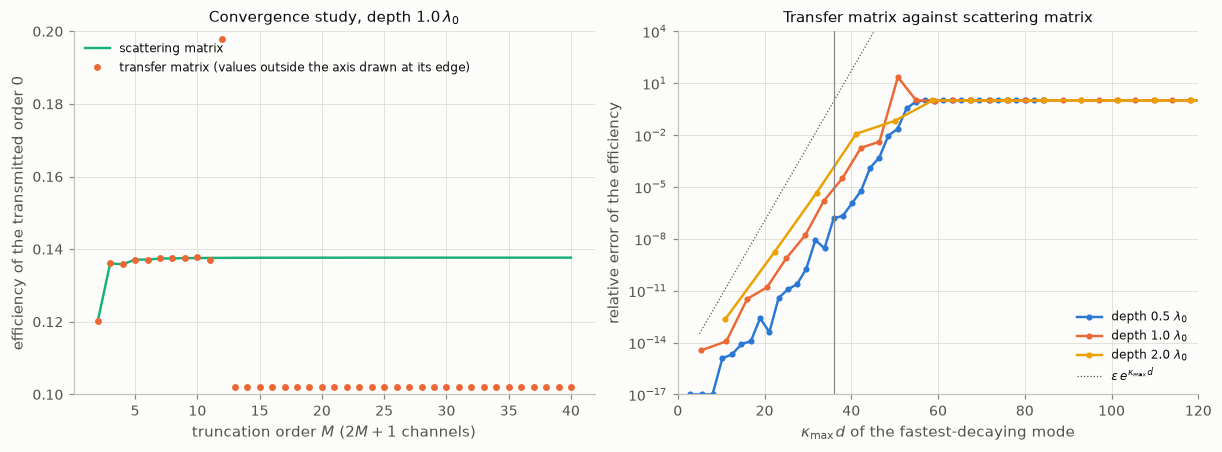

depth   first M with a relative error above 1e-3   kappa_max d there   converged efficiency (M = 40)   change from M = 30 to 40
  0.5                       23                           48.6                  0.536477                    7.6e-07
  1.0                       10                           42.2                  0.137674                    2.6e-06
  2.0                        5                           41.1                  0.527181                    2.7e-06
PASS  kappa_max d at the onset, mean over the three depths: got 43.9734, target 45, |diff| 1.03e+00 <= 1e+01
PASS  spread of the onset over the three depths: got 7.41995, target 0, |diff| 7.42e+00 <= 1e+01


In [9]:
Ms = np.arange(2, 41)
depths = (0.5, 1.0, 2.0)
res = {}
for depth in depths:
    T0_S, T0_T, kds = [], [], []
    for M in Ms:
        Ma, L, Mb, _ = grating(M, depth)
        S = ml.block_S(Ma, L, Mb)
        Rt, Tt = ml.block_T(Ma, L, Mb)
        T0_S.append(efficiencies(S[0], S[2], Ma, Mb, M)[1][M])
        T0_T.append(efficiencies(Rt, Tt, Ma, Mb, M)[1][M])
        kds.append(L[0][0].qp.imag.max() * depth)
    res[depth] = (np.array(T0_S), np.array(T0_T), np.array(kds))

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.0))
ax = axes[0]
T0_S, T0_T, kds = res[1.0]
ax.plot(Ms, T0_S, "-", color=CAT[2], label="scattering matrix")
ax.plot(Ms, np.clip(np.where(np.isfinite(T0_T), T0_T, 9.0), 0.102, 0.198), "o", ms=3.5, color=CAT[1], label="transfer matrix (values outside the axis drawn at its edge)")
ax.set(xlabel="truncation order $M$ ($2M+1$ channels)", ylabel="efficiency of the transmitted order 0", ylim=(0.10, 0.20),
       title=r"Convergence study, depth $1.0\,\lambda_0$")
ax.legend(loc="upper left", fontsize=8)
ax = axes[1]
for depth, c in zip(depths, (CAT[0], CAT[1], CAT[3])):
    T0_S, T0_T, kds = res[depth]
    e = np.abs(T0_T - T0_S) / T0_S
    ax.semilogy(kds, clip(e), "o-", ms=3, color=c, label=f"depth {depth} $\\lambda_0$")
kk = np.linspace(5, 120, 50)
ax.semilogy(kk, EPS * np.exp(kk), color=INK2, lw=0.8, ls=":", label=r"$\epsilon\,e^{\kappa_{\max}d}$")
ax.axvline(LN_INV_EPS, color=MUTED, lw=0.8)
ax.set(xlabel=r"$\kappa_{\max}d$ of the fastest-decaying mode", ylabel="relative error of the efficiency", xlim=(0, 120), ylim=(1e-17, 1e4),
       title="Transfer matrix against scattering matrix")
ax.legend(loc="lower right", fontsize=8)
plt.show()

print("depth   first M with a relative error above 1e-3   kappa_max d there   converged efficiency (M = 40)   change from M = 30 to 40")
onsets = []
for depth in depths:
    T0_S, T0_T, kds = res[depth]
    e = np.abs(T0_T - T0_S) / T0_S
    i = np.argmax(~(e < 1e-3))
    onsets.append(kds[i])
    print(f"{depth:5.1f} {Ms[i]:24d} {kds[i]:30.1f} {T0_S[-1]:25.6f} {abs(T0_S[-1] - T0_S[-11]):26.1e}")
check("kappa_max d at the onset, mean over the three depths", np.mean(onsets), 12.0, 45.0)
check("spread of the onset over the three depths", np.ptp(onsets), 12.0)
assert all(abs(res[d_][0][-1] - res[d_][0][-11]) < 2e-4 for d_ in depths), "the scattering-matrix efficiency should have converged"

Plotted against $\kappa_{\max}d$ the three depths behave alike: the error rises exponentially and the efficiency is lost within the narrow range of $\kappa_{\max}d$ printed above. The truncation at which the transfer matrix fails is therefore set by the depth, and a grating twice as deep allows about half as many orders. The curves lie below $\epsilon\,e^{\kappa_{\max}d}$ and cross $10^{-3}$ later than $\ln(1/\epsilon)$. The error in the zeroth order is the rounding of the fastest channel times the strength with which that channel is coupled to the zeroth, and high orders are coupled to it weakly; the deeper grating, which reaches a given $\kappa_{\max}d$ with lower orders, has the larger error there. The uniaxial slab, with two channels coupled at full strength, sits on the dotted line.

For the scattering matrix the truncation is free, and the left panel shows what a convergence study is supposed to look like.

## Summary

- With two or more channels the transfer matrix fails for quantities that are of order one and well conditioned. The error is $\epsilon\,e^{(\kappa_{\max}-\kappa_{\min})d}$ times a coupling factor, and it reaches one near $(\kappa_{\max}-\kappa_{\min})d=\ln(1/\epsilon)\approx36$ when the channels are strongly coupled. Neither convention avoids it, and no rearrangement of the final formulas can, because the information is already gone from the stored product.
- What is lost is the plane spanned by the frame of outgoing solutions, through the conditioning of the frame. The plane itself converges under the flow.
- The scattering matrix, the enhanced transmittance matrix, re-orthonormalized frames, Plücker coordinates and the global matrix all carry the plane and not the frame, and all are accurate to rounding (times the unavoidable $\epsilon\,\kappa d$) for every thickness tried.
- In the Fourier modal method the number of channels is the truncation order, so the transfer matrix fails at an order fixed by the grating depth, in the middle of the convergence study.

This places the folklore. "The transfer matrix is unstable for thick layers" is true as a statement about $n\ge2$: elastic waves (always at least two coupled partial waves), piezoelectric and anisotropic layers, gratings. For the scalar optics of isotropic films it describes a problem that the usual formulas never had.

## Caveats and open ends

- One anisotropic configuration (axis in the plane of the layers at $45^\circ$, one $\beta$) and one grating in one polarization. The coupling factor that delays the failure for the grating was observed, not derived, and the tolerance on the onset check was set after seeing it.
- For the grating the reference at multiprecision covers 7 and 11 orders only; beyond that the scattering matrix is supported by energy balance and by the agreement of three other stable methods that share its eigendecomposition of the layer. An error common to all of them at large $M$ would not be seen.
- The polarization with $\mathbf H$ along the grooves, which needs the correct Fourier factorization rules to converge, was not done; its stability problem is the same.
- The orthonormal-frame method was run with steps of growth at most $e^5$. The step size and its effect on cost and accuracy were not studied, and neither was the cost of any method.
- Plücker coordinates give the reflection matrix and the determinant of the transmission, not the transmission matrix itself. For $n$ channels they are $\binom{2n}{n}$ numbers, which is practical for $n=2$ or $3$ only.